In [1]:
"""
Compare logical performance between Qiskit Aer and Stim backends across
different noise scaling factors.

This mirrors experiments/noise_scaling/p_scaling.py but runs the same logical
permutation scan twice per noise scale: once with the standard AerSimulator
backend and once with the Stim backend. It then plots the resulting logical
fidelities and selection rates to highlight any mismatch between the two
simulation pipelines.
"""
from __future__ import annotations

import sys
from pathlib import Path

# Ensure project root is on sys.path so `import pipeline` works even when the
# notebook is launched from a subdirectory.
def _find_repo_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "pipeline").is_dir() and (candidate / "simulator").is_dir():
            return candidate
    return start

repo_root = _find_repo_root(Path.cwd().resolve())
if str(repo_root) not in sys.path:
    sys.path.append(str(repo_root))

from typing import List, Tuple

import matplotlib.pyplot as plt
from matplotlib import ticker
import numpy as np
import qiskit
from qiskit.circuit import QuantumCircuit
from qiskit.circuit.random import random_clifford_circuit

from pipeline import run_specific_scan
from pipeline.config import PipelineConfig
from simulator.config_presets import StandardSimulator
from simulator.noise_models import ScaledNoiseModel


In [2]:
"""
Compare logical performance between Qiskit Aer and Stim backends across
different noise scaling factors.

This mirrors experiments/noise_scaling/p_scaling.py but runs the same logical
permutation scan twice per noise scale: once with the standard AerSimulator
backend and once with the Stim backend. It then plots the resulting logical
fidelities and selection rates to highlight any mismatch between the two
simulation pipelines.
"""
import sys
sys.path.append("../")
from __future__ import annotations

from concurrent.futures import ThreadPoolExecutor, as_completed
import os
from typing import List, Tuple

import matplotlib.pyplot as plt
from matplotlib import ticker
import numpy as np
import qiskit
from qiskit.circuit import QuantumCircuit
from qiskit.circuit.random import random_clifford_circuit

from pipeline import run_specific_scan
from pipeline.config import PipelineConfig
from simulator.config_presets import StandardSimulator
from simulator.noise_models import ScaledNoiseModel

# Representative permutations (same as p_scaling experiment)
PERM_GROUP = [(0, 0), (0, 1), (1, 0), (1, 1)]
PERM_DIFF = [(0, 0), (1, 0), (2, 0), (3, 0)]
PERMUTATIONS: List[List[Tuple[int, int]]] = [PERM_GROUP, PERM_DIFF]

TARGET_BASIS = ["x", "z", "h", "rz", "cx", "cz", "measure"]


def build_circuit(seed: int = 17, qubits: int = 4, depth: int = 25) -> QuantumCircuit:
    """Generate and transpile a random Clifford circuit for the experiment."""
    program_circuit = random_clifford_circuit(
        qubits,
        depth,
        seed=seed,
        gates=["x", "h", "z", "s", "cx", "cz"],
    )
    program_circuit.measure_all()
    # return qiskit.transpile(
    #     program_circuit,
    #     basis_gates=TARGET_BASIS,
    #     optimization_level=0,
    # )
    return program_circuit

def run_scan_with_backend(
    tcirc: QuantumCircuit,
    sim_config: PipelineConfig,
):
    """Convenience wrapper for run_specific_scan so we can swap configs."""
    return run_specific_scan(
        program_circuit=tcirc,
        permutations=PERMUTATIONS,
        config=sim_config,
    )


def compute_fidelity_mismatch(
    circuits: List[QuantumCircuit],
    scalars: np.ndarray,
    *,
    repetitions: int,
) -> np.ndarray:
    """
    For each circuit and noise scaling factor, return the Stim-vs-Aer fidelity mismatch.
    Returns an array of shape (num_circuits, len(scalars)).
    """
    mismatches = np.zeros((len(circuits), len(scalars)), dtype=float)

    for ci, tcirc in enumerate(circuits):
        for si, scalar in enumerate(scalars):
            noise_model = ScaledNoiseModel(alpha=scalar)

            aer_sim = (
                StandardSimulator(repetitions=repetitions)
                .with_noise_model(noise_model)
                .with_stim(False)
            )
            stim_sim = (
                StandardSimulator(repetitions=repetitions)
                .with_noise_model(noise_model)
                .with_stim(True)
                .with_stim_scaling(None)
            )

            aer_config = PipelineConfig(sim_config=aer_sim, verbose=False, save=False)
            stim_config = PipelineConfig(sim_config=stim_sim, verbose=False, save=False)

            aer_record = run_specific_scan(
                program_circuit=tcirc,
                permutations=PERMUTATIONS,
                config=aer_config,
            )
            stim_record = run_specific_scan(
                program_circuit=tcirc,
                permutations=PERMUTATIONS,
                config=stim_config,
            )

            aer_fidelity = 1 - aer_record.dataframe.df.loc[
                0, "logical_total_variation_distance"
            ]
            stim_fidelity = 1 - stim_record.dataframe.df.loc[
                0, "logical_total_variation_distance"
            ]
            denom = aer_fidelity if aer_fidelity != 0 else 1.0
            mismatch_pct = 100.0 * abs(aer_fidelity - stim_fidelity) / denom
            mismatches[ci, si] = mismatch_pct
            print(
                f"[circuit {ci + 1}/{len(circuits)}] "
                f"alpha={scalar:.3e} | Aer={aer_fidelity:.4f}, "
                f"Stim={stim_fidelity:.4f}, Δ={mismatch_pct:+.4f}%"
            )

    return mismatches





In [9]:
def plot_mismatch(
    scalars: np.ndarray,
    mismatches: np.ndarray,
    output_path: str,
) -> None:
    """
    Plot the mean/σ/min/max fidelity mismatch as a function of noise scale.
    """
    # Filter out columns where all entries are zero to avoid log issues
    valid_mask = np.any(mismatches > 0, axis=0)
    valid_scalars = scalars[valid_mask]
    filtered = mismatches[:, valid_mask]
    if filtered.size == 0:
        print("No positive mismatch values to plot.")
        return

    mean = np.mean(filtered, axis=0)
    std = np.std(filtered, axis=0)
    min_vals = np.min(filtered, axis=0)
    max_vals = np.max(filtered, axis=0)

    fig, ax = plt.subplots(figsize=(8, 4.5), facecolor="white")
    ax.set_facecolor("white")

    ax.set_xscale("log")
    # ax.set_yscale("log")

    ax.plot(valid_scalars, mean, color="#1454d0", linewidth=3, label="Mean mismatch")
    # ax.fill_between(
    #     valid_scalars,
    #     np.clip(mean - std, 1e-12, None),
    #     np.clip(mean + std, 1e-12, None),
    #     color="#1454d0",
    #     alpha=0.35,
    #     label="±1σ",
    # )
    ax.fill_between(
        valid_scalars,
        np.clip(min_vals, 1e-12, None),
        np.clip(max_vals, 1e-12, None),
        color="#1454d0",
        alpha=0.25,
        label="Min–max",
    )
    ax.set_xlabel("Noise scale (α)")
    ax.set_ylabel("Fidelity mismatch % (Aer − Stim)")
    ax.set_title("Stim vs Aer fidelity mismatch across random circuits")
    ax.legend(loc="upper left", frameon=False)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(True, which="major", linestyle="--", alpha=0.45)
    ax.xaxis.set_minor_locator(ticker.NullLocator())

    plt.tight_layout()
    plt.savefig(output_path, format="svg", facecolor=fig.get_facecolor())
    print(f"Saved mismatch plot to {output_path}")


In [4]:
num_circuits = 20
repetitions = 500
scalars = np.logspace(-1.5, 1.5, num=20)

circuits = [
    build_circuit(seed=1000 + idx, qubits=4, depth=25)
    for idx in range(num_circuits)
]


In [5]:
test_mismatches = compute_fidelity_mismatch(
    circuits,
    scalars,
    repetitions=repetitions,
)


Simulating circuits: 100%|██████████| 2/2 [00:00<00:00, 158.91 sim/s]


[circuit 1/20] alpha=3.162e-02 | Aer=0.9421, Stim=0.9479, Δ=+0.6236%


Simulating circuits: 100%|██████████| 2/2 [00:00<00:00, 161.23 sim/s]


[circuit 1/20] alpha=4.549e-02 | Aer=0.9385, Stim=0.9696, Δ=+3.3062%


Simulating circuits: 100%|██████████| 2/2 [00:00<00:00, 162.34 sim/s]


...

[circuit 20/20] alpha=1.528e+01 | Aer=0.2000, Stim=0.0000, Δ=+100.0000%


Simulating circuits: 100%|██████████| 2/2 [00:00<00:00, 155.53 sim/s]


[circuit 20/20] alpha=2.198e+01 | Aer=0.1667, Stim=0.0909, Δ=+45.4545%


Simulating circuits: 100%|██████████| 2/2 [00:00<00:00, 155.53 sim/s]

[circuit 20/20] alpha=3.162e+01 | Aer=0.0000, Stim=0.1250, Δ=+12.5000%


Saved mismatch plot to stim_vs_aer_fidelity_mismatch.svg


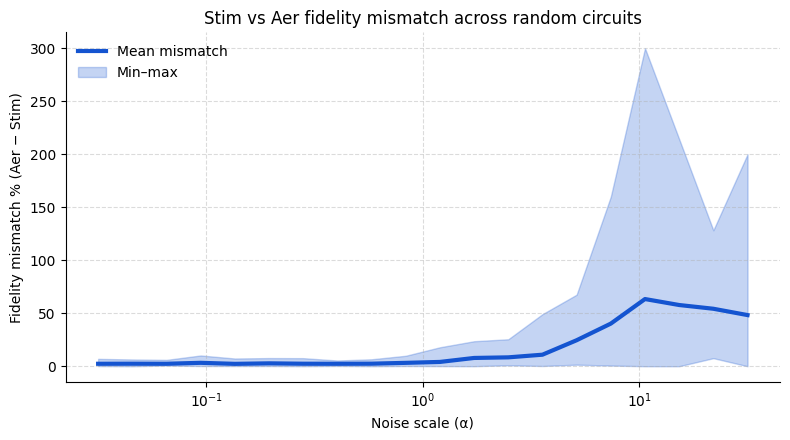

In [10]:

plot_mismatch(
    scalars,
    test_mismatches,
    output_path="stim_vs_aer_fidelity_mismatch.svg",
)